# DNN Model: Telco Customer Churn Prediction
**Course:** Deep Learning | **Midterm Project**

---

## 1. Problem Definition

Customer churn refers to when customers discontinue their subscription to a service. For telecom companies, retaining existing customers is significantly more cost-effective than acquiring new ones.

**Problem:** Given a customer's demographic information, account details, and usage patterns, predict whether that customer will churn (leave the service).

**Type:** Binary Classification (Churn: Yes / No)

**Business Value:** Early identification of at-risk customers allows the company to take targeted retention actions, reducing revenue loss.

## 2. Dataset Description

- **Dataset Name:** Telco Customer Churn
- **Source:** [Kaggle - Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
- **Rows:** 7,043 customers | **Columns:** 21 (20 features + 1 target)
- **Target Variable:** `Churn` (Yes/No)

| Category | Features |
|---|---|
| Demographics | gender, SeniorCitizen, Partner, Dependents |
| Account Info | tenure, Contract, PaperlessBilling, PaymentMethod |
| Services | PhoneService, MultipleLines, InternetService, OnlineSecurity, etc. |
| Financials | MonthlyCharges, TotalCharges |

## 3. Proposed Solution

A Deep Neural Network (DNN) is proposed. DNNs are well-suited for tabular classification tasks where the relationship between features and the target is non-linear. The model will:

1. Accept preprocessed customer features as input
2. Learn complex patterns through multiple hidden layers with Dropout regularization
3. Output a probability score indicating churn likelihood

Class weight balancing addresses the imbalanced target distribution (~73% No Churn vs ~27% Churn).

## 4. Data Preprocessing

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import joblib

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


In [4]:
# Mount Google Drive (run once per session)
from google.colab import drive
drive.mount('/content/drive')

# Load dataset from Drive
df = pd.read_csv('/content/drive/MyDrive/WA_Fn-UseC_-Telco-Customer-Churn.csv')
print('Shape:', df.shape)
df.head()

Mounted at /content/drive
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


/tmp/ipykernel_412/2911410002.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=df, palette='Set2')


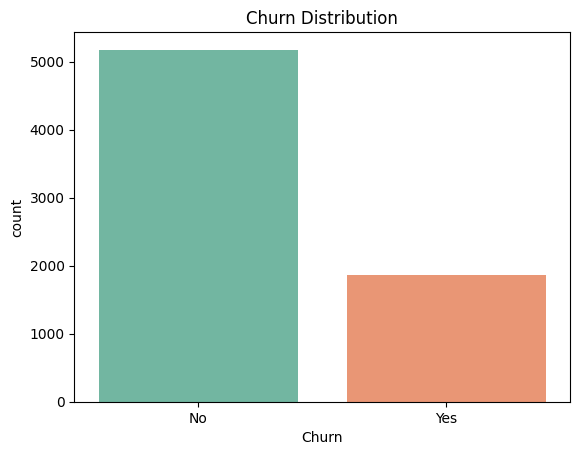

In [5]:
# Class distribution
print('Target distribution:')
print(df['Churn'].value_counts())

sns.countplot(x='Churn', data=df, palette='Set2')
plt.title('Churn Distribution')
plt.show()

In [6]:
# Drop customerID
df = df.drop('customerID', axis=1)

# Fix TotalCharges
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# Encode target
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Encode categorical columns
cat_cols = df.select_dtypes(include='object').columns
le = LabelEncoder()
for col in cat_cols:
    df[col] = le.fit_transform(df[col])

print('Preprocessing complete. Shape:', df.shape)
df.head()

Preprocessing complete. Shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


In [7]:
# Split features and target
X = df.drop('Churn', axis=1)
y = df['Churn']

# Train/test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature scaling
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print('Train size:', X_train_s.shape)
print('Test size:', X_test_s.shape)

Train size: (5634, 19)
Test size: (1409, 19)


In [8]:
# Compute class weights for imbalance
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {0: class_weights[0], 1: class_weights[1]}
print('Class weights:', class_weight_dict)

Class weights: {0: np.float64(0.6805991785455424), 1: np.float64(1.8842809364548494)}


## 5. Model Architecture

| Layer | Units | Activation | Notes |
|---|---|---|---|
| Input | 19 | - | One node per feature |
| Dense 1 | 128 | ReLU | First hidden layer |
| Dropout | 30% | - | Regularization |
| Dense 2 | 64 | ReLU | Second hidden layer |
| Dropout | 30% | - | Regularization |
| Dense 3 | 32 | ReLU | Third hidden layer |
| Output | 1 | Sigmoid | Binary classification |

In [9]:
def build_dnn(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(32, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])
    return model

model = build_dnn(X_train_s.shape[1])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,929 (50.50 KB)

 Trainable params: 12,929 (50.50 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True
)

history = model.fit(
    X_train_s, y_train,
    epochs=100, batch_size=32,
    validation_split=0.2,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.7091 - auc: 0.7879 - loss: 0.5556 - val_accuracy: 0.6859 - val_auc: 0.8151 - val_loss: 0.5611
Epoch 2/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7435 - auc: 0.8321 - loss: 0.5032 - val_accuracy: 0.6921 - val_auc: 0.8178 - val_loss: 0.5441
Epoch 3/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7426 - auc: 0.8392 - loss: 0.4926 - val_accuracy: 0.7178 - val_auc: 0.8189 - val_loss: 0.5074
Epoch 4/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7479 - auc: 0.8447 - loss: 0.4872 - val_accuracy: 0.6983 - val_auc: 0.8210 - val_loss: 0.5562
Epoch 5/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7533 - auc: 0.8457 - loss: 0.4878 - val_accuracy: 0.7152 - val_auc: 0.8212 - val_loss: 0.5147
Epoch 6/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7488 - auc: 0.8508 - loss: 0.4761 - val_accuracy: 0.7152 - val_auc: 0.8210 - val_loss: 0.5194
Epoch 7/100
141/141 ━━━━━━━━━━━━━

## 6. Training Results and Evaluation

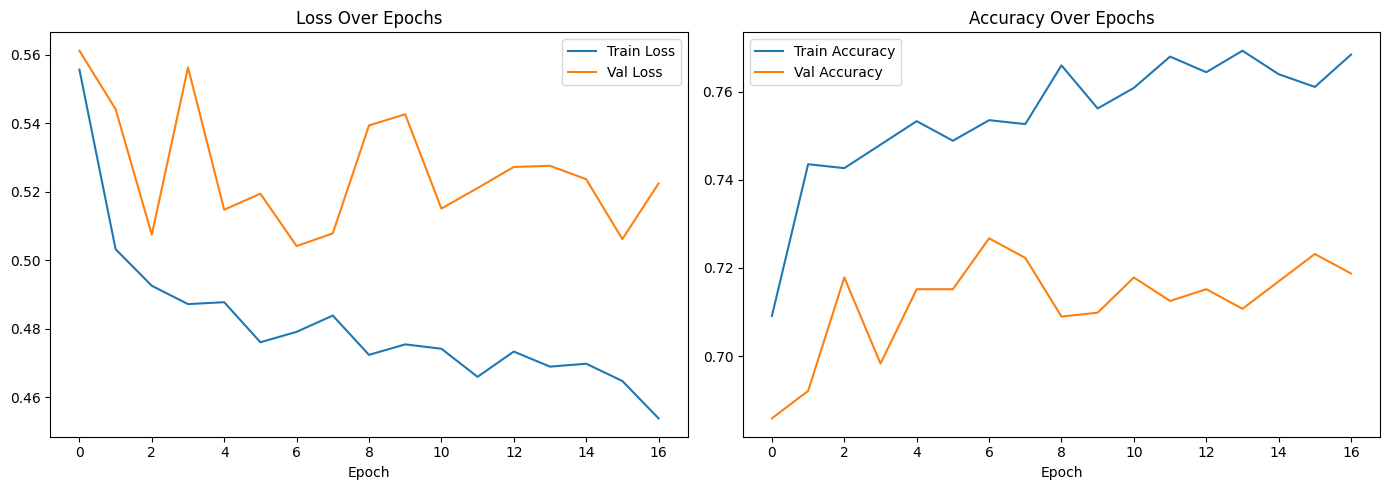

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Loss Over Epochs'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(history.history['accuracy'], label='Train Accuracy')
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[1].set_title('Accuracy Over Epochs'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout(); plt.show()

In [12]:
test_loss, test_acc, test_auc = model.evaluate(X_test_s, y_test, verbose=0)
print(f'Test Accuracy: {test_acc:.4f}')
print(f'Test AUC:      {test_auc:.4f}')
print(f'Test Loss:     {test_loss:.4f}')

Test Accuracy: 0.7438
Test AUC:      0.8330
Test Loss:     0.4873


In [13]:
y_pred_prob = model.predict(X_test_s).flatten()
y_pred = (y_pred_prob >= 0.5).astype(int)
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
              precision    recall  f1-score   support

    No Churn       0.89      0.74      0.81      1035
       Churn       0.51      0.76      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.79      0.74      0.76      1409



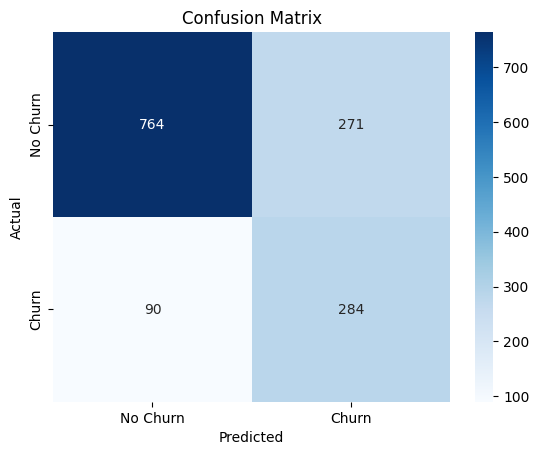

In [14]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.title('Confusion Matrix'); plt.ylabel('Actual'); plt.xlabel('Predicted'); plt.show()

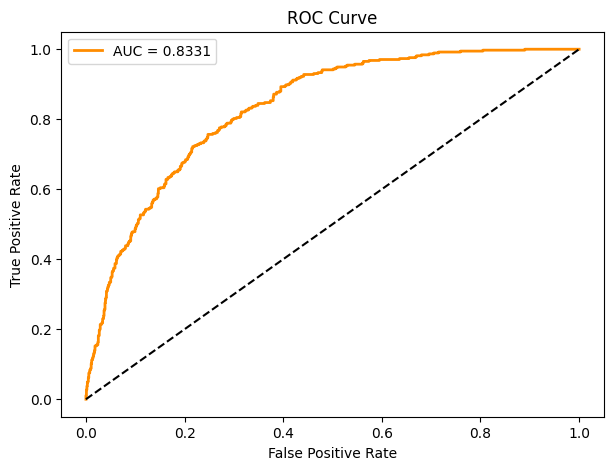

In [15]:
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
auc_score = roc_auc_score(y_test, y_pred_prob)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {auc_score:.4f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve'); plt.legend(); plt.show()

## 6a. Baseline Comparison (Logistic Regression)
To check whether the DNN is better than a simple model, I trained a logistic regression on the same scaled data with the same class weights, and compared both on the test set.

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

lr = LogisticRegression(max_iter=1000, class_weight='balanced')
lr.fit(X_train_s, y_train)
lr_prob = lr.predict_proba(X_test_s)[:, 1]
lr_pred = (lr_prob >= 0.5).astype(int)

comparison = pd.DataFrame({
    'Logistic Regression': [accuracy_score(y_test, lr_pred), precision_score(y_test, lr_pred),
                            recall_score(y_test, lr_pred), f1_score(y_test, lr_pred), roc_auc_score(y_test, lr_prob)],
    'DNN': [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
            recall_score(y_test, y_pred), f1_score(y_test, y_pred), roc_auc_score(y_test, y_pred_prob)]
}, index=['Accuracy', 'Precision (churn)', 'Recall (churn)', 'F1 (churn)', 'ROC-AUC']).round(4)
comparison

,Logistic Regression,DNN
Accuracy,0.7395,0.7438
Precision (churn),0.5059,0.5117
Recall (churn),0.7968,0.7594
F1 (churn),0.6189,0.6114
ROC-AUC,0.8396,0.8331


## 6b. Inference Step

The inference step demonstrates the trained model making a prediction on a **new, unseen customer** — simulating real-world deployment.

In [21]:
# --- INFERENCE ON A SINGLE NEW CUSTOMER ---
# Feature order must match X_train columns
# Values below represent one customer's encoded attributes

# Example: Female, Non-senior, has Partner, no Dependents,
# tenure=24, PhoneService=Yes, MultipleLines=No, InternetService=Fiber,
# OnlineSecurity=No, OnlineBackup=Yes, DeviceProtection=No, TechSupport=No,
# StreamingTV=Yes, StreamingMovies=Yes, Contract=Month-to-month,
# PaperlessBilling=Yes, PaymentMethod=Electronic check,
# MonthlyCharges=85.25, TotalCharges=2046.0

new_customer = pd.DataFrame([{
    'gender': 0,              # Female=0, Male=1
    'SeniorCitizen': 0,
    'Partner': 1,
    'Dependents': 0,
    'tenure': 24,
    'PhoneService': 1,
    'MultipleLines': 0,
    'InternetService': 1,     # Fiber optic
    'OnlineSecurity': 0,
    'OnlineBackup': 1,
    'DeviceProtection': 0,
    'TechSupport': 0,
    'StreamingTV': 1,
    'StreamingMovies': 1,
    'Contract': 0,            # Month-to-month
    'PaperlessBilling': 1,
    'PaymentMethod': 2,       # Electronic check
    'MonthlyCharges': 85.25,
    'TotalCharges': 2046.0
}])

# Scale using the same scaler fitted on training data
new_customer_scaled = scaler.transform(new_customer)

# Predict
churn_prob = model.predict(new_customer_scaled, verbose=0)[0][0]
prediction = 'Churn' if churn_prob >= 0.5 else 'No Churn'

print('=' * 40)
print('       INFERENCE RESULT')
print('=' * 40)
print(f'Churn Probability : {churn_prob:.4f} ({churn_prob*100:.1f}%)')
print(f'Prediction        : {prediction}')
print('=' * 40)

       INFERENCE RESULT
Churn Probability : 0.7753 (77.5%)
Prediction        : Churn


In [22]:
# --- BATCH INFERENCE on multiple customers ---
# Take 5 random test customers and show predictions
sample_indices = np.random.choice(len(X_test_s), 5, replace=False)
sample_inputs = X_test_s[sample_indices]
sample_true = y_test.iloc[sample_indices].values

sample_probs = model.predict(sample_inputs, verbose=0).flatten()
sample_preds = (sample_probs >= 0.5).astype(int)

print('Batch Inference Results:')
print('-' * 55)
print(f'{"Customer":<12} {"True Label":<15} {"Predicted":<15} {"Probability"}')
print('-' * 55)
labels = {0: 'No Churn', 1: 'Churn'}
for i in range(5):
    print(f'{i+1:<12} {labels[sample_true[i]]:<15} {labels[sample_preds[i]]:<15} {sample_probs[i]:.4f}')

Batch Inference Results:
-------------------------------------------------------
Customer     True Label      Predicted       Probability
-------------------------------------------------------
1            No Churn        Churn           0.5123
2            No Churn        No Churn        0.1213
3            No Churn        No Churn        0.0095
4            No Churn        Churn           0.7229
5            No Churn        No Churn        0.0548


## 7. Save Model in .joblib Format

In [23]:
# Save model + scaler + feature names together
joblib.dump({
    'model': model,
    'scaler': scaler,
    'feature_names': list(X.columns)
}, '/content/drive/MyDrive/dnn_churn_model.joblib')

print('Model saved to Google Drive as dnn_churn_model.joblib')

Model saved to Google Drive as dnn_churn_model.joblib


In [24]:
# Load and verify the saved model
saved = joblib.load('/content/drive/MyDrive/dnn_churn_model.joblib')
loaded_model = saved['model']
loaded_scaler = saved['scaler']

# Verify inference works with loaded model
verify_prob = loaded_model.predict(new_customer_scaled, verbose=0)[0][0]
print(f'Loaded model prediction: {verify_prob:.4f} -> {"Churn" if verify_prob >= 0.5 else "No Churn"}')
print('Model loaded and verified successfully.')

Loaded model prediction: 0.7753 -> Churn
Model loaded and verified successfully.


## 8. Conclusion

This project developed a Deep Neural Network to predict customer churn using the Telco Customer Churn dataset:

- **Preprocessing:** Label encoding, TotalCharges fix, StandardScaler normalization
- **Class imbalance** handled with computed class weights
- **Architecture:** 3-hidden-layer DNN (128 → 64 → 32 → Sigmoid) with Dropout regularization
- **Inference:** Demonstrated on both single new customer and batch predictions
- **Saved:** Model + scaler packaged in `.joblib` for deployment

